# Projet 4 (simple): U-Net on return sequences

**The big picture, in 5 steps**
1. For each date we look at the last 60 daily returns of 15 stocks.
2. A neural network (a 1-D U-Net) turns them into 16 portfolio weights (15 stocks + cash). Weights are >= 0 and sum to 1.
3. We train it with three different **losses** (ways of scoring a prediction): MSE, cross-entropy and Sharpe, and compare them.
4. We try several **U-Net architectures** (width, depth, kernel, pooling, upsampling, type of skip connection) and
   **training hyperparameters** (dropout, learning rate, weight decay, batch size) for each loss, and choose on the validation set.
5. We compare the result to the **oracle** (best possible portfolio, computed with the future - a cheat used as upper bound)
   and to simple **baselines** (k-NN, rolling Markowitz, equal weight).

Only the return sequence is used as input (no other features).

**Vocabulary**
* *weights*: share of the portfolio put in each asset (0.10 = 10 %).
* *Sharpe ratio*: return divided by risk. Higher is better.
* *turnover*: how much the portfolio changes at each rebalancing. High turnover = high trading costs.
* *train / val / test*: train = the model learns, val = we choose between options, test = final honest score (never used for choices).


## 0. Setup and data

In [14]:
import sys, random, copy, json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Find the project folder so we can import the data loader
ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT / "data_generation"))
from build_dataset import load_dataset, MarkowitzSolver, ASSETS

DATA_FOLDER = ROOT / "data/processed/N63_wmax1"
RESULTS_FOLDER = Path("results")
FIGURES_FOLDER = Path("figures")
FIGURES_FOLDER.mkdir(exist_ok=True)

# ----- Settings you can change -----
HORIZON = 63                      # days. The oracle looks 63 days ahead, and we rebalance every 63 days
FEE = 0.001                       # trading cost: 0.1 % of what we trade
PERIODS_PER_YEAR = 252 / HORIZON  # used to express Sharpe / volatility per year
SEEDS = [0, 1, 2]                 # we train 3 networks per loss and average them (less random)


def set_seed(seed):
    # Fix all random number generators so that results can be reproduced
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [15]:
data = load_dataset(DATA_FOLDER)

features = data["X"].to_numpy(np.float32)         # tabular features (only used by the k-NN baseline here)
oracle_weights = data["Y"].to_numpy(np.float32)   # target: best weights computed with the future ("Y")
future_returns = data["R_fwd"].to_numpy(np.float32)  # what each asset really returned over the next 63 days
sequences = data["X_seq"].astype(np.float32)      # (samples, 60 days, 15 stocks): the network input
dates = data["X"].index
label_end = data["meta"]["label_end"].to_numpy()  # date at which each oracle label stops looking ahead

# Row numbers of each part of the data (split by time, so no peeking at the future)
train_idx, val_idx, test_idx = data["train_idx"], data["val_idx"], data["test_idx"]

for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    print(f"{name:5s} {len(idx)} samples  {dates[idx[0]].date()} -> {dates[idx[-1]].date()}")

train 2749 samples  2006-01-02 -> 2016-10-03
val   703 samples  2017-01-02 -> 2019-10-02
test  1474 samples  2020-01-02 -> 2025-09-30


**Scaling.** Neural networks train better when inputs are of order 1. We divide by the standard deviation measured on the
**training** part only (using val/test here would leak information).

In [16]:
# Scale the return sequences (one std per stock, measured on train only)
seq_std = sequences[train_idx].reshape(-1, sequences.shape[2]).std(axis=0) + 1e-8
seq_scaled = (sequences / seq_std).astype(np.float32)

# Scale the tabular features the same way (standardise, then clip outliers to +-5)
feat_mean = features[train_idx].mean(axis=0)
feat_std = features[train_idx].std(axis=0) + 1e-8
feat_scaled = np.clip((features - feat_mean) / feat_std, -5, 5).astype(np.float32)

# Typical variance of the oracle weights (used to put MSE on the same scale as Sharpe in the 'mix' loss)
oracle_variance = oracle_weights[train_idx].var(axis=0).mean()

## 1. The model: a 1-D U-Net

Think of the 60 days of returns as a 15-channel signal (like a 15-channel audio clip).

* **Encoder (going down)**: convolutions look for patterns, then the signal is shortened (60 -> 30 -> 15 days) so deeper layers see longer-range patterns.
* **Decoder (going up)**: the signal is stretched back (15 -> 30 -> 60). **Skip connections** copy the detailed early layers into the decoder (this is the "U" shape).
* **Head**: we take the last day and the average over time, and a small layer turns them into 16 numbers.
* **Softmax**: converts those 16 numbers into weights that are positive and sum to 1.

The U-Net below has knobs so that we can try several architectures in section 6:

| Knob | Default | Meaning |
|---|---|---|
| `channels` | 16 | width of the first level (doubles at each level down) |
| `depth` | 2 | number of times the signal is halved (2: 60 -> 30 -> 15) |
| `kernel` | 5 | number of days each convolution looks at |
| `pool` | `max` | how the signal is shortened: keep the max (`max`) or the average (`avg`) of 2 days |
| `upsample` | `nearest` | how it is stretched back: repeat values (`nearest`), straight line between them (`linear`), or a learned layer (`transposed`) |
| `skip` | `concat` | how skip connections are merged: stacked side by side (`concat`), summed (`add`), or removed (`none`, no "U" any more) |

The default is exactly the network described above.


In [17]:
def conv_block(in_channels, out_channels, dropout, kernel=5):
    # Two convolutions. BatchNorm keeps values stable, GELU is the activation, Dropout fights overfitting.
    return nn.Sequential(
        nn.Conv1d(in_channels, out_channels, kernel_size=kernel, padding=kernel // 2),
        nn.BatchNorm1d(out_channels),
        nn.GELU(),
        nn.Dropout(dropout),
        nn.Conv1d(out_channels, out_channels, kernel_size=kernel, padding=kernel // 2),
        nn.BatchNorm1d(out_channels),
        nn.GELU(),
    )


def make_head(in_features, dropout, n_outputs=16):
    # Small fully-connected layer: features -> 16 numbers (15 stocks + cash)
    return nn.Sequential(nn.Linear(in_features, 64), nn.GELU(), nn.Dropout(dropout), nn.Linear(64, n_outputs))


class UNet(nn.Module):
    def __init__(self, n_stocks=15, channels=16, depth=2, kernel=5, dropout=0.2,
                 pool="max", upsample="nearest", skip="concat"):
        super().__init__()
        self.pool, self.upsample, self.skip = pool, upsample, skip
        widths = [channels * 2 ** i for i in range(depth + 1)]   # e.g. [16, 32, 64]: doubles at each level
        # Encoder: one block per level; the last one is the bottom of the "U"
        self.encoders = nn.ModuleList(
            [conv_block(n_stocks, widths[0], dropout, kernel)]
            + [conv_block(widths[i], widths[i + 1], dropout, kernel) for i in range(depth)])

        levels = list(reversed(range(depth)))              # decoder goes back up: level depth-1, ..., 0
        # Learned upsampling (only for upsample="transposed")
        self.ups = nn.ModuleList([
            nn.ConvTranspose1d(widths[i + 1], widths[i + 1], kernel_size=2, stride=2) if upsample == "transposed"
            else nn.Identity() for i in levels])
        # For skip="add": a 1x1 convolution so the upsampled signal has as many channels as the skip
        self.projections = nn.ModuleList([
            nn.Conv1d(widths[i + 1], widths[i], kernel_size=1) if skip == "add" else nn.Identity() for i in levels])
        decoder_inputs = {"concat": [widths[i + 1] + widths[i] for i in levels],   # side by side: sum of channels
                          "add":    [widths[i] for i in levels],
                          "none":   [widths[i + 1] for i in levels]}[skip]
        self.decoders = nn.ModuleList(
            [conv_block(n_in, widths[i], dropout, kernel) for n_in, i in zip(decoder_inputs, levels)])
        self.head = make_head(2 * widths[0], dropout)

    def forward(self, x):
        h = x.transpose(1, 2)                              # (batch, days, stocks) -> (batch, stocks, days)

        skips = []
        for level, encoder in enumerate(self.encoders):
            if level > 0:                                  # halve the number of days (60 -> 30 -> 15)
                h = F.max_pool1d(h, 2) if self.pool == "max" else F.avg_pool1d(h, 2)
            h = encoder(h)
            skips.append(h)

        h = skips.pop()                                    # bottom of the "U"
        for up, projection, decoder in zip(self.ups, self.projections, self.decoders):
            skip = skips.pop()
            h = up(h)                                      # learned upsampling (does nothing unless "transposed")
            mode = "linear" if self.upsample == "linear" else "nearest"
            h = F.interpolate(h, size=skip.shape[-1], mode=mode)   # stretch back to the size of the skip
            if self.skip == "concat":
                h = torch.cat([h, skip], dim=1)
            elif self.skip == "add":
                h = projection(h) + skip
            h = decoder(h)

        last_day = h[..., -1]                              # what just happened
        average = h.mean(dim=-1)                           # overall picture of the 60 days
        logits = self.head(torch.cat([last_day, average], dim=1))
        return F.softmax(logits, dim=-1)                   # weights: >= 0, sum to 1


# Default settings (architecture + training). A config in section 6 only lists what it changes.
DEFAULT_CONFIG = dict(channels=16, depth=2, kernel=5, pool="max", upsample="nearest", skip="concat",
                      dropout=0.2, lr=1e-3, weight_decay=1e-3, batch_size=128)
ARCHITECTURE_KEYS = ["channels", "depth", "kernel", "dropout", "pool", "upsample", "skip"]


def build_model(config):
    c = {**DEFAULT_CONFIG, **config}
    return UNet(**{key: c[key] for key in ARCHITECTURE_KEYS})


n_params = sum(p.numel() for p in build_model({}).parameters())
print(n_params, "parameters")


70592 parameters


## 2. The three losses and the training loop

A **loss** says how bad a prediction is; training tries to make it small.

| Loss | Idea |
|---|---|
| `mse` | Copy the oracle: penalise the squared gap between predicted and oracle weights. |
| `ce` | Copy the oracle, but treat both weight vectors as probability distributions and use the **cross-entropy** $-\sum_i w^{oracle}_i \log w^{pred}_i$. It punishes much harder than MSE a near-zero weight on an asset the oracle buys. |
| `sharpe` | Ignore the oracle. Directly maximise the Sharpe ratio of the portfolio return (we minimise minus Sharpe). |

**Early stopping**: after each epoch (one pass over the training data) we measure the loss on the validation data.
We keep the best version and stop when it has not improved for 10 epochs. This stops the network from memorising the training set.

Each (config, loss) pair is trained with 3 seeds and the 3 predictions are averaged (`train_ensemble`). Results are
cached, so the same pair is never trained twice in this notebook.


In [18]:
def compute_loss(pred_weights, oracle_w, fwd_returns, kind):
    if kind == "mse":
        # how far are we from the oracle weights?
        return ((pred_weights - oracle_w) ** 2).mean()

    if kind == "ce":
        # cross-entropy between the oracle weights and the predicted weights (both sum to 1)
        return -(oracle_w * torch.log(pred_weights.clamp_min(1e-8))).sum(dim=1).mean()

    if kind == "sharpe":
        # how good is the portfolio? (return above cash, divided by its variability)
        portfolio_return = (pred_weights * fwd_returns).sum(dim=1)
        cash_return = fwd_returns[:, -1]                   # last column = cash
        excess = portfolio_return - cash_return
        return -excess.mean() / (excess.std() + 1e-8)      # minus, because training *minimises*

    raise ValueError(kind)


def rows(array, idx):
    # Take the given rows of a numpy array and turn them into a torch tensor
    return torch.from_numpy(array[idx])


def train_one_model(loss_kind, seed, config=None, max_epochs=60, patience=10):
    c = {**DEFAULT_CONFIG, **(config or {})}
    set_seed(seed)
    model = build_model(c)
    optimizer = torch.optim.AdamW(model.parameters(), lr=c["lr"], weight_decay=c["weight_decay"])
    batch_size = c["batch_size"]

    best_val_loss = np.inf
    best_state = None
    epochs_without_progress = 0

    for epoch in range(max_epochs):
        # ---- learn on the training data, in shuffled mini-batches ----
        model.train()
        shuffled = np.random.permutation(train_idx)
        for start in range(0, len(shuffled), batch_size):
            batch = shuffled[start:start + batch_size]
            if len(batch) < 16:
                continue                                   # too small a batch makes BatchNorm / Sharpe unstable
            pred = model(rows(seq_scaled, batch))
            loss = compute_loss(pred, rows(oracle_weights, batch), rows(future_returns, batch), loss_kind)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # ---- check the validation loss (no learning here) ----
        model.eval()
        with torch.no_grad():
            pred = model(rows(seq_scaled, val_idx))
            val_loss = compute_loss(pred, rows(oracle_weights, val_idx), rows(future_returns, val_idx), loss_kind).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())  # remember the best version so far
            epochs_without_progress = 0
        else:
            epochs_without_progress += 1
            if epochs_without_progress >= patience:
                break                                      # early stopping

    model.load_state_dict(best_state)
    return model.eval()


def predict_weights(models, idx):
    # Average the predictions of several models (an "ensemble")
    with torch.no_grad():
        all_preds = [m(rows(seq_scaled, idx)).numpy() for m in models]
    return np.mean(all_preds, axis=0)


ensemble_cache = {}   # (config name, loss) -> {"val": weights, "test": weights}


def train_ensemble(config_name, config, loss):
    # Train one model per seed, return the averaged weights on val and test (cached)
    key = (config_name, loss)
    if key not in ensemble_cache:
        models = [train_one_model(loss, seed, config) for seed in SEEDS]
        ensemble_cache[key] = {"val": predict_weights(models, val_idx), "test": predict_weights(models, test_idx)}
    return ensemble_cache[key]


In [19]:
LOSSES = ["mse", "ce", "sharpe"]

# First, the default U-Net with each loss (3 seeds each)
predictions = {loss: train_ensemble("default", {}, loss) for loss in LOSSES}
print("done training:", LOSSES)


done training: ['mse', 'ce', 'sharpe']


## 3. Backtest: what would this strategy have earned?

* Every 63 days we set the portfolio to the predicted weights and hold it.
* Return over the period = sum of (weight x asset return). We subtract the trading cost = 0.1 % x turnover.
* Between two rebalancings prices move, so the weights drift; turnover is measured against the *drifted* weights.
* With 63-day periods there are only a few rebalancings, so the result depends on the start day. We repeat the backtest
  for the 63 possible start days and **average** the metrics.

In [20]:
def simulate(weights, period_returns):
    # weights, period_returns: one row per rebalancing date
    drifted = weights * (1 + period_returns)                         # weights after prices moved...
    drifted = drifted / drifted.sum(axis=1, keepdims=True)           # ...renormalised to sum to 1

    turnover = np.zeros(len(weights))                                # first rebalancing is free
    turnover[1:] = np.abs(weights[1:] - drifted[:-1]).sum(axis=1)

    total_return = (weights * period_returns).sum(axis=1) - FEE * turnover
    excess_return = total_return - period_returns[:, -1]             # compared to just holding cash
    return total_return, excess_return, turnover


def backtest(weights, idx):
    returns = future_returns[idx]
    results = []
    for start in range(HORIZON):                                     # try every start day
        rebalance_days = np.arange(start, len(idx), HORIZON)         # every 63rd day
        total, excess, turnover = simulate(weights[rebalance_days], returns[rebalance_days])
        wealth = np.cumprod(1 + total)                               # growth of 1 euro
        results.append({
            "total_return": wealth[-1] - 1,
            "vol": total.std() * np.sqrt(PERIODS_PER_YEAR),
            "sharpe": excess.mean() / (excess.std() + 1e-12) * np.sqrt(PERIODS_PER_YEAR),
            "max_dd": (wealth / np.maximum.accumulate(wealth) - 1).min(),   # worst fall from a peak
            "turnover": turnover[1:].mean(),
        })
    return pd.DataFrame(results).mean().to_dict()                    # average over the start days


def wealth_curve(weights, idx):
    # Growth of 1 euro over time (start day 0 only, for plotting)
    rebalance_days = np.arange(0, len(idx), HORIZON)
    total, _, _ = simulate(weights[rebalance_days], future_returns[idx][rebalance_days])
    return dates[idx][rebalance_days], np.cumprod(1 + total)


def evaluate(strategies, idx):
    # strategies: {name: weights}. Returns one table row per strategy.
    table = {}
    for name, weights in strategies.items():
        row = backtest(weights, idx)
        row["mse_vs_oracle"] = ((weights - oracle_weights[idx]) ** 2).mean()   # how close to the oracle
        table[name] = row
    return pd.DataFrame(table).T

## 4. Baselines to compare with

* **k-NN**: look at the k most similar days in the *past*, and average the oracle weights of those days. (k picked on val.)
* **Rolling Markowitz**: classic max-Sharpe portfolio computed on the last 63 days of returns.
* **Equal weight**: 1/15 in every stock.
* **Oracle**: the best portfolio with hindsight. Not achievable; it is the ceiling.

In [21]:
# For each date: how many past samples have an already-known label? (their label window ended before today)
n_known = np.searchsorted(label_end, dates.to_numpy(), side="left")


def knn_weights(idx, k):
    out = np.zeros((len(idx), 16), np.float32)
    for row, t in enumerate(idx):
        past = feat_scaled[:n_known[t]]                              # only the past
        distance = ((past - feat_scaled[t]) ** 2).sum(axis=1)        # distance to every past day
        nearest = np.argpartition(distance, k)[:k]                   # the k closest days
        out[row] = oracle_weights[nearest].mean(axis=0)              # average of their oracle weights
    return out


# Choose k on the validation set
knn_val_sharpe = {k: backtest(knn_weights(val_idx, k), val_idx)["sharpe"] for k in [5, 20, 50, 100]}
best_k = max(knn_val_sharpe, key=knn_val_sharpe.get)
print("k-NN validation Sharpe:", {k: round(v, 2) for k, v in knn_val_sharpe.items()}, "-> k =", best_k)

k-NN validation Sharpe: {5: 0.93, 20: 0.95, 50: 0.94, 100: 1.02} -> k = 100


In [22]:
daily_returns = pd.read_csv(DATA_FOLDER / "returns.csv", index_col=0, parse_dates=True)
daily_array = daily_returns.to_numpy()
row_in_daily = daily_returns.index.get_indexer(dates)
solver = MarkowitzSolver(15, 1.0)                                    # same solver that built the oracle


def rolling_markowitz(idx):
    out = np.zeros((len(idx), 16), np.float32)
    for row, j in enumerate(idx):
        last_63_days = daily_array[row_in_daily[j] - HORIZON + 1: row_in_daily[j] + 1]
        # daily risk-free rate, derived from the cash return of the previous period
        daily_cash = (1 + future_returns[j - HORIZON, -1]) ** (1 / HORIZON) - 1
        out[row] = solver.solve(last_63_days, np.full(HORIZON, daily_cash))[0]
    return out


def make_baselines(idx):
    equal = np.tile(np.r_[np.full(15, 1 / 15), 0.0], (len(idx), 1)).astype(np.float32)   # 1/15 each, 0 cash
    return {
        f"k-NN (k={best_k})": knn_weights(idx, best_k),
        "Rolling Markowitz": rolling_markowitz(idx),
        "Equal weight": equal,
        "Oracle (upper bound)": oracle_weights[idx],
    }


baselines = {"val": make_baselines(val_idx), "test": make_baselines(test_idx)}

## 5. Results

How to read the table:
* `sharpe` - higher is better (main score).
* `total_return`, `vol` (yearly volatility), `max_dd` (worst drop; closer to 0 is better).
* `turnover` - lower = cheaper to run.
* `mse_vs_oracle` - how far the weights are from the oracle's.

We pick the best loss on **val**, then look at **test**.

In [23]:
tables = {}
for split, idx in [("val", val_idx), ("test", test_idx)]:
    strategies = {f"U-Net seq [{loss}]": predictions[loss][split] for loss in LOSSES}
    strategies.update(baselines[split])
    tables[split] = evaluate(strategies, idx)

    print(f"\n=== {split.upper()}  ({dates[idx[0]].date()} -> {dates[idx[-1]].date()}) ===")
    display(tables[split].round(3))

# Best loss = highest Sharpe on the validation set
best_loss = max(LOSSES, key=lambda l: tables["val"].loc[f"U-Net seq [{l}]", "sharpe"])
print("best loss on validation Sharpe:", best_loss)


=== VAL  (2017-01-02 -> 2019-10-02) ===


,total_return,vol,sharpe,max_dd,turnover,mse_vs_oracle
U-Net seq [mse],0.375,0.110,1.164,-0.077,0.065,0.022
U-Net seq [ce],0.383,0.111,1.174,-0.078,0.060,0.022
U-Net seq [sharpe],0.538,0.109,1.550,-0.044,0.772,0.035
k-NN (k=100),0.343,0.117,1.016,-0.093,0.822,0.028
Rolling Markowitz,0.291,0.119,0.844,-0.101,1.611,0.042
Equal weight,0.360,0.119,1.041,-0.098,0.052,0.023
Oracle (upper bound),2.489,0.113,4.409,-0.000,1.675,0.000



=== TEST  (2020-01-02 -> 2025-09-30) ===


,total_return,vol,sharpe,max_dd,turnover,mse_vs_oracle
U-Net seq [mse],0.965,0.150,0.799,-0.104,0.123,0.020
U-Net seq [ce],0.948,0.151,0.789,-0.106,0.104,0.020
U-Net seq [sharpe],0.671,0.141,0.624,-0.122,0.645,0.033
k-NN (k=100),1.029,0.169,0.764,-0.108,0.756,0.023
Rolling Markowitz,0.563,0.191,0.421,-0.192,1.608,0.039
Equal weight,1.143,0.164,0.843,-0.118,0.076,0.020
Oracle (upper bound),28.933,0.128,4.890,0.000,1.594,0.000


best loss on validation Sharpe: sharpe


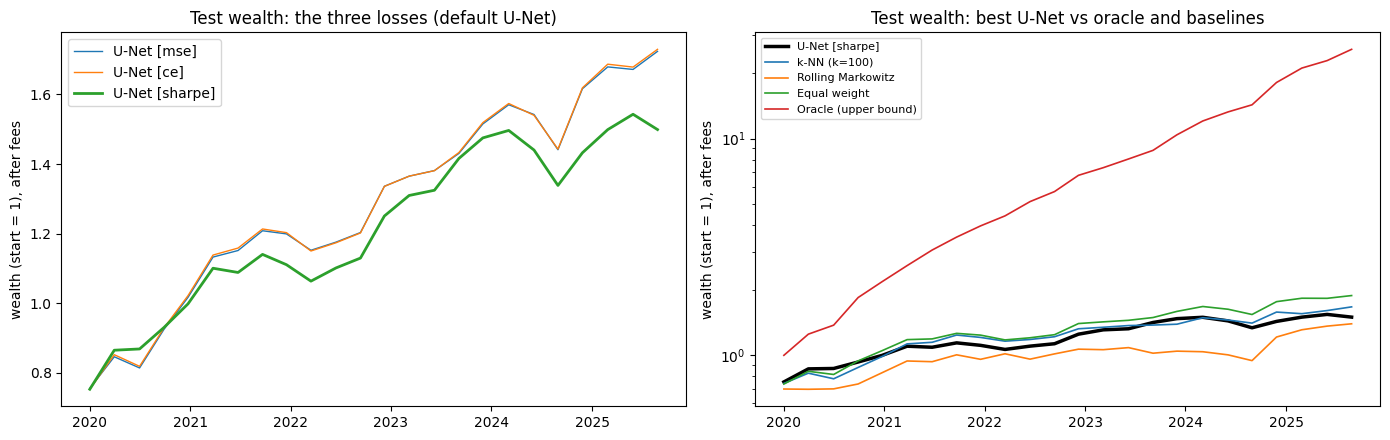

In [24]:
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4.5))

# Left: compare the three losses
for loss in LOSSES:
    d, w = wealth_curve(predictions[loss]["test"], test_idx)
    left.plot(d, w, label=f"U-Net [{loss}]", lw=2 if loss == best_loss else 1)
left.set_title("Test wealth: the three losses (default U-Net)")
left.legend()

# Right: best U-Net vs oracle and baselines (log scale because the oracle grows enormously)
d, w = wealth_curve(predictions[best_loss]["test"], test_idx)
right.plot(d, w, label=f"U-Net [{best_loss}]", lw=2.5, color="black")
for name, weights in baselines["test"].items():
    d, w = wealth_curve(weights, test_idx)
    right.plot(d, w, label=name, lw=1.2)
right.set_yscale("log")
right.set_title("Test wealth: best U-Net vs oracle and baselines")
right.legend(fontsize=8)

for ax in (left, right):
    ax.set_ylabel("wealth (start = 1), after fees")
plt.tight_layout()
plt.savefig(FIGURES_FOLDER / "simple_wealth_test.png", dpi=130)
plt.show()

## 6. U-Net architectures and hyperparameters

The default U-Net was picked by hand. Here we change **one setting at a time** from the default and retrain, **for each of the
three losses**:

* **Architecture**: narrower / wider (`channels` 8, 32), shallower / deeper (`depth` 1, 3), shorter / longer `kernel` (3, 7),
  average pooling, linear or learned (`transposed`) upsampling, skip connections summed (`add`) or removed (`none`).
* **Training**: no / more `dropout` (0, 0.4), smaller / larger learning rate (3e-4, 3e-3), stronger weight decay (1e-2),
  smaller / bigger batches (64, 256 - this matters for the `sharpe` loss, which estimates a Sharpe ratio on each batch).

Every (config, loss) pair is an ensemble of 3 seeds, scored with the same backtest as above. **We choose on validation Sharpe
only.** With this many candidates the best validation score is partly luck, so the test column is the one to trust; the scatter
plot below shows how well validation predicts test.


In [25]:
SEARCH_CONFIGS = {
    "default":            {},
    # --- architecture ---
    "channels=8":         {"channels": 8},
    "channels=32":        {"channels": 32},
    "depth=1":            {"depth": 1},
    "depth=3":            {"depth": 3},
    "kernel=3":           {"kernel": 3},
    "kernel=7":           {"kernel": 7},
    "pool=avg":           {"pool": "avg"},
    "upsample=linear":    {"upsample": "linear"},
    "upsample=transposed": {"upsample": "transposed"},
    "skip=add":           {"skip": "add"},
    "skip=none":          {"skip": "none"},
    # --- training ---
    "dropout=0":          {"dropout": 0.0},
    "dropout=0.4":        {"dropout": 0.4},
    "lr=3e-4":            {"lr": 3e-4},
    "lr=3e-3":            {"lr": 3e-3},
    "weight_decay=1e-2":  {"weight_decay": 1e-2},
    "batch=64":           {"batch_size": 64},
    "batch=256":          {"batch_size": 256},
}

search_rows = []
for name, config in SEARCH_CONFIGS.items():
    n_params = sum(p.numel() for p in build_model(config).parameters())
    for loss in LOSSES:
        preds = train_ensemble(name, config, loss)
        val_metrics, test_metrics = backtest(preds["val"], val_idx), backtest(preds["test"], test_idx)
        search_rows.append({
            "config": name, "loss": loss, "n_params": n_params,
            "val_sharpe": val_metrics["sharpe"], "test_sharpe": test_metrics["sharpe"],
            "test_return": test_metrics["total_return"], "test_max_dd": test_metrics["max_dd"],
            "test_turnover": test_metrics["turnover"],
            "test_mse_vs_oracle": ((preds["test"] - oracle_weights[test_idx]) ** 2).mean(),
        })
    print(f"done: {name}")

search = pd.DataFrame(search_rows)
(RESULTS_FOLDER / "search").mkdir(parents=True, exist_ok=True)
search.to_csv(RESULTS_FOLDER / "search" / "search_results.csv", index=False)
display(search.sort_values("val_sharpe", ascending=False).round(3).reset_index(drop=True))


done: default
done: channels=8
done: channels=32
done: depth=1
done: depth=3
done: kernel=3
done: kernel=7
done: pool=avg
done: upsample=linear
done: upsample=transposed
done: skip=add
done: skip=none
done: dropout=0
done: dropout=0.4
done: lr=3e-4
done: lr=3e-3
done: weight_decay=1e-2
done: batch=64
done: batch=256


,config,loss,n_params,val_sharpe,test_sharpe,test_return,test_max_dd,test_turnover,test_mse_vs_oracle
0,lr=3e-3,sharpe,70592,1.726,0.495,0.569,-0.131,0.878,0.033
1,channels=32,sharpe,270640,1.723,0.653,0.803,-0.124,0.716,0.044
2,batch=64,sharpe,70592,1.587,0.561,0.709,-0.170,0.645,0.035
3,default,sharpe,70592,1.550,0.624,0.671,-0.122,0.645,0.033
4,dropout=0,sharpe,70592,1.549,0.587,0.473,-0.097,0.852,0.033
5,weight_decay=1e-2,sharpe,70592,1.547,0.641,0.688,-0.117,0.548,0.033
6,depth=3,sharpe,276544,1.518,0.472,0.561,-0.182,0.874,0.044
7,upsample=linear,sharpe,70592,1.497,0.575,0.591,-0.115,0.620,0.031
8,pool=avg,sharpe,70592,1.493,0.559,0.557,-0.115,0.518,0.030
9,skip=add,sharpe,60400,1.490,0.477,0.561,-0.140,0.527,0.031


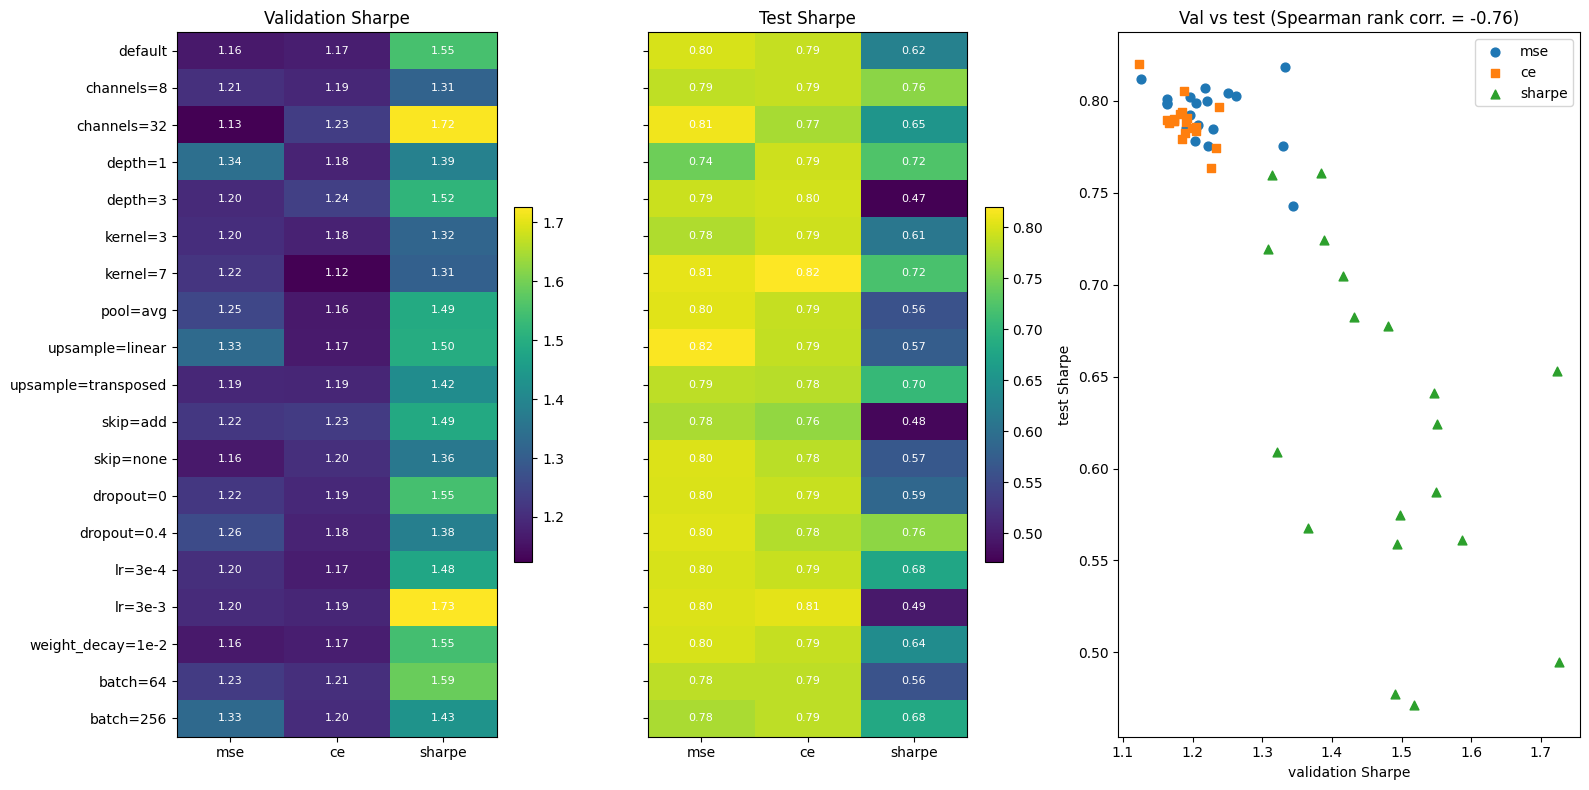

In [26]:
val_grid = search.pivot(index="config", columns="loss", values="val_sharpe").loc[list(SEARCH_CONFIGS), LOSSES]
test_grid = search.pivot(index="config", columns="loss", values="test_sharpe").loc[list(SEARCH_CONFIGS), LOSSES]

fig, axes = plt.subplots(1, 3, figsize=(16, 8), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, grid, title in [(axes[0], val_grid, "Validation Sharpe"), (axes[1], test_grid, "Test Sharpe")]:
    image = ax.imshow(grid.to_numpy(), cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(LOSSES)), LOSSES)
    ax.set_yticks(range(len(grid)), grid.index)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            ax.text(j, i, f"{grid.iat[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
    ax.set_title(title)
    fig.colorbar(image, ax=ax, fraction=0.05)
axes[1].set_yticklabels([])

# Does a good validation score mean a good test score?
markers = {"mse": "o", "ce": "s", "sharpe": "^"}
for loss in LOSSES:
    part = search[search["loss"] == loss]
    axes[2].scatter(part["val_sharpe"], part["test_sharpe"], marker=markers[loss], label=loss, s=40)
correlation = search[["val_sharpe", "test_sharpe"]].corr(method="spearman").iat[0, 1]
axes[2].set_xlabel("validation Sharpe")
axes[2].set_ylabel("test Sharpe")
axes[2].set_title(f"Val vs test (Spearman rank corr. = {correlation:.2f})")
axes[2].legend()
plt.tight_layout()
plt.savefig(FIGURES_FOLDER / "search_heatmaps.png", dpi=130, bbox_inches="tight")
plt.show()


### The three losses, each with its best config

For each loss we keep the config with the best **validation** Sharpe, then compare the three on test, next to the baselines.


best config per loss (chosen on val): {'mse': 'depth=1', 'ce': 'depth=3', 'sharpe': 'lr=3e-3'}

=== VAL ===


,total_return,vol,sharpe,max_dd,turnover,mse_vs_oracle
U-Net depth=1 [mse],0.447,0.110,1.345,-0.062,0.226,0.021
U-Net depth=3 [ce],0.403,0.109,1.238,-0.073,0.114,0.022
U-Net lr=3e-3 [sharpe],0.615,0.110,1.726,-0.048,0.790,0.035
k-NN (k=100),0.343,0.117,1.016,-0.093,0.822,0.028
Rolling Markowitz,0.291,0.119,0.844,-0.101,1.611,0.042
Equal weight,0.360,0.119,1.041,-0.098,0.052,0.023
Oracle (upper bound),2.489,0.113,4.409,-0.000,1.675,0.000



=== TEST ===


,total_return,vol,sharpe,max_dd,turnover,mse_vs_oracle
U-Net depth=1 [mse],0.881,0.153,0.743,-0.110,0.241,0.021
U-Net depth=3 [ce],0.957,0.150,0.796,-0.102,0.165,0.020
U-Net lr=3e-3 [sharpe],0.569,0.154,0.495,-0.131,0.878,0.033
k-NN (k=100),1.029,0.169,0.764,-0.108,0.756,0.023
Rolling Markowitz,0.563,0.191,0.421,-0.192,1.608,0.039
Equal weight,1.143,0.164,0.843,-0.118,0.076,0.020
Oracle (upper bound),28.933,0.128,4.890,0.000,1.594,0.000


overall best on val: lr=3e-3 [sharpe]  val Sharpe 1.73  test Sharpe 0.49


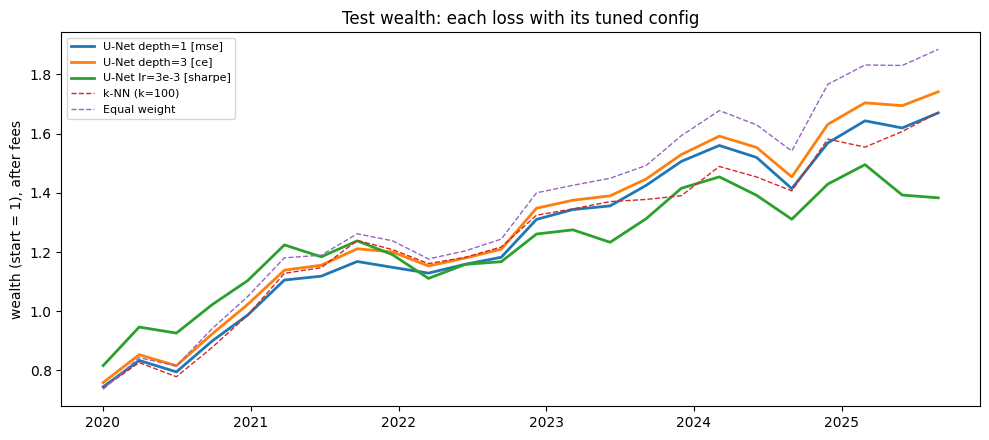

In [27]:
best_config = {loss: search[search["loss"] == loss].sort_values("val_sharpe").iloc[-1]["config"] for loss in LOSSES}
print("best config per loss (chosen on val):", best_config)

tuned = {loss: ensemble_cache[(best_config[loss], loss)] for loss in LOSSES}
tuned_tables = {}
for split, idx in [("val", val_idx), ("test", test_idx)]:
    strategies = {f"U-Net {best_config[loss]} [{loss}]": tuned[loss][split] for loss in LOSSES}
    strategies.update(baselines[split])
    tuned_tables[split] = evaluate(strategies, idx)
    print(f"\n=== {split.upper()} ===")
    display(tuned_tables[split].round(3))

# Overall winner = best validation Sharpe across all (config, loss) pairs
winner = search.sort_values("val_sharpe").iloc[-1]
winner_name, winner_loss = winner["config"], winner["loss"]
winner_preds = ensemble_cache[(winner_name, winner_loss)]
print(f"overall best on val: {winner_name} [{winner_loss}]  val Sharpe {winner['val_sharpe']:.2f}  test Sharpe {winner['test_sharpe']:.2f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
for loss in LOSSES:
    d, w = wealth_curve(tuned[loss]["test"], test_idx)
    ax.plot(d, w, label=f"U-Net {best_config[loss]} [{loss}]", lw=2)
for name in [f"k-NN (k={best_k})", "Equal weight"]:
    d, w = wealth_curve(baselines["test"][name], test_idx)
    ax.plot(d, w, label=name, lw=1, ls="--")
ax.set_title("Test wealth: each loss with its tuned config")
ax.set_ylabel("wealth (start = 1), after fees")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_FOLDER / "tuned_wealth_test.png", dpi=130)
plt.show()


## 7. What the weights look like

Weights of the overall winner of section 6 (best validation Sharpe).

Each colour is one asset. At every date the coloured bands stack up to 1 (= 100 % of the portfolio), so the **thickness of a band is that
asset's weight**. Big single-colour blocks mean a concentrated bet.

The oracle changes its mind all the time because it is the best portfolio *with hindsight*. The network cannot predict that,
so its allocation is smoother.


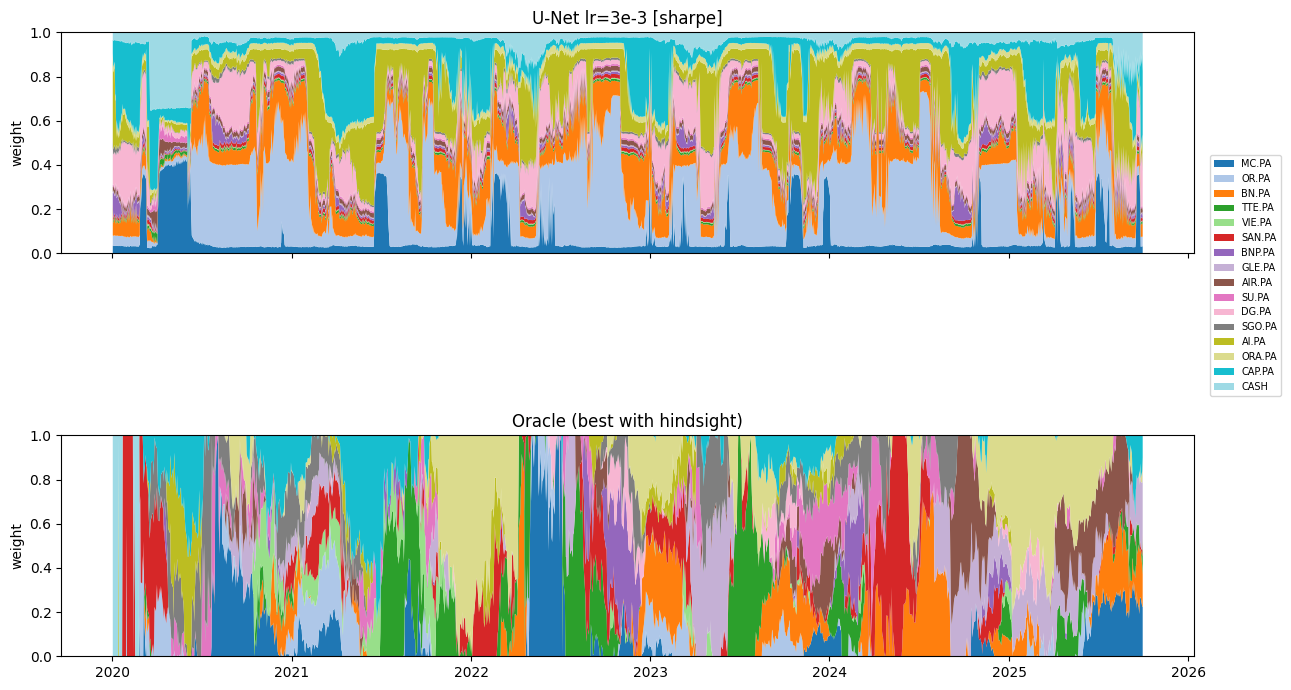

Average weight on test:


,MC.PA,OR.PA,BN.PA,TTE.PA,VIE.PA,SAN.PA,BNP.PA,GLE.PA,AIR.PA,SU.PA,DG.PA,SGO.PA,AI.PA,ORA.PA,CAP.PA,CASH
U-Net,0.075,0.240,0.131,0.010,0.003,0.016,0.018,0.005,0.022,0.009,0.099,0.010,0.157,0.027,0.123,0.054
Oracle,0.080,0.043,0.078,0.097,0.029,0.101,0.030,0.082,0.060,0.047,0.016,0.072,0.036,0.142,0.072,0.014


In [28]:
colors = plt.get_cmap("tab20")(np.linspace(0, 1, 16))               # 16 distinct colours

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
panels = [(f"U-Net {winner_name} [{winner_loss}]", winner_preds["test"]),
          ("Oracle (best with hindsight)", oracle_weights[test_idx])]
for ax, (title, weights) in zip(axes, panels):
    ax.stackplot(dates[test_idx], weights.T, labels=ASSETS, colors=colors)
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.set_ylabel("weight")
axes[0].legend(ncol=1, fontsize=7, loc="center left", bbox_to_anchor=(1.01, -0.1))
plt.tight_layout()
plt.savefig(FIGURES_FOLDER / "simple_weights_test.png", dpi=130, bbox_inches="tight")
plt.show()

print("Average weight on test:")
display(pd.DataFrame({"U-Net": winner_preds["test"].mean(axis=0),
                      "Oracle": oracle_weights[test_idx].mean(axis=0)}, index=ASSETS).round(3).T)

## 8. Save the chosen run
Writes weights, config and metrics in `results/unet_seq_only/` (format used by `synthesis/compare_models.ipynb`).
The saved run is the (config, loss) pair with the best validation Sharpe in section 6. The full search table is in `results/search/search_results.csv`.


In [29]:
chosen_name, chosen_loss, chosen_preds = winner_name, winner_loss, winner_preds
print(f"saving: {chosen_name} [{chosen_loss}]")

folder = RESULTS_FOLDER / "unet_seq_only"
folder.mkdir(parents=True, exist_ok=True)

for split, idx in [("val", val_idx), ("test", test_idx)]:
    weights_table = pd.DataFrame(chosen_preds[split], index=dates[idx].rename("date"), columns=ASSETS)
    weights_table.to_csv(folder / f"weights_{split}.csv", float_format="%.8g")

config = dict(model="unet", use_seq=True, use_tab=False, loss=chosen_loss, config_name=chosen_name,
              hyperparameters={**DEFAULT_CONFIG, **SEARCH_CONFIGS[chosen_name]},
              seeds=SEEDS, horizon=HORIZON, fee=FEE)
json.dump(config, open(folder / "config.json", "w"), indent=2)

metrics = pd.DataFrame({split: evaluate({"x": chosen_preds[split]}, idx).loc["x"]
                        for split, idx in [("val", val_idx), ("test", test_idx)]}).T
metrics.to_csv(folder / "metrics.csv")
display(metrics.round(3))
print("saved in", folder)


saving: lr=3e-3 [sharpe]


,total_return,vol,sharpe,max_dd,turnover,mse_vs_oracle
val,0.615,0.110,1.726,-0.048,0.790,0.035
test,0.569,0.154,0.495,-0.131,0.878,0.033


saved in results\unet_seq_only
